### گام اول : پیش پردازش و پرهیز از نشت داده

In [1]:
import pandas as pd

Full_data = pd.read_csv("austin_commute_raw.csv")

### 1.

In [2]:
Full_data["dispatched_on"] = pd.to_datetime(
    Full_data["dispatched_on"], utc=True, errors="coerce"
)

Full_data["driver_reached_on"] = pd.to_datetime(
    Full_data["driver_reached_on"], utc=True, errors="coerce"
)

Full_data["time_diff"] = (
    Full_data["driver_reached_on"] - Full_data["dispatched_on"]
).dt.total_seconds() / 60

Full_data["on_time"] = pd.NA

valid = Full_data["time_diff"].notna()

Full_data.loc[valid, "on_time"] = (
    Full_data.loc[valid, "time_diff"] <= 5
).astype(int)

class_counts = Full_data.loc[valid, "on_time"].value_counts().sort_index()
class_percentages = (
    Full_data.loc[valid, "on_time"].value_counts(normalize=True).sort_index() * 100
)

print("Class counts:")
print(class_counts)

print("\nClass percentages:")
print(class_percentages.round(2))

print("\nMissing target values:", Full_data["on_time"].isna().sum())


Class counts:
on_time
0    62849
1    87013
Name: count, dtype: int64

Class percentages:
on_time
0    41.94
1    58.06
Name: proportion, dtype: float64

Missing target values: 138


### 2.

In [3]:

import pandas as pd
import ast
import re

columns = [
    "year",
    "make",
    "model",
    "color",
    "requested_car_category",
    "status"
]

unique_before = Full_data[columns].nunique(dropna=True)

def decode_bytes(value):
    if pd.isna(value):
        return value

    if isinstance(value, bytes):
        return value.decode("utf-8", errors="replace")

    if isinstance(value, str):
        value = value.strip()

        if value.startswith("b'") or value.startswith('b"'):
            try:
                decoded = ast.literal_eval(value)
                if isinstance(decoded, bytes):
                    return decoded.decode("utf-8", errors="replace")
            except (ValueError, SyntaxError):
                pass

        return value

    return value



for col in columns:
    Full_data[col] = Full_data[col].apply(decode_bytes)


Full_data["year"] = pd.to_numeric(
    Full_data["year"], errors="coerce"
).astype("Int64")


text_columns = [
    "make",
    "model",
    "color",
    "requested_car_category",
    "status"
]

for col in text_columns:
    Full_data[col] = Full_data[col].apply(
        lambda x: re.sub(r"\s+", " ", x).strip().lower()
        if isinstance(x, str) else x
    )


make_mapping = {
    "chevy": "chevrolet",
    "mercedes benz": "mercedes-benz",
    "merceded benz": "mercedes-benz",
    "mercedes": "mercedes-benz",
    "infinity": "infiniti",
    "toytoa": "toyota",
    "volkwagen": "volkswagen",
    "licoln": "lincoln",
    "tessla": "tesla",
    "mini cooper": "mini",
    "sienna": "toyota"
}

Full_data["make"] = Full_data["make"].replace(make_mapping)


unique_after = Full_data[columns].nunique(dropna=True)

comparison = pd.DataFrame({
    "Unique Before": unique_before,
    "Unique After": unique_after,
    "Difference": unique_before - unique_after
})

print(comparison)
print("on_time" in Full_data.columns)
print(Full_data["on_time"].value_counts(dropna=False))

                        Unique Before  Unique After  Difference
year                               18            18           0
make                               62            40          22
model                             424           410          14
color                              32            24           8
requested_car_category              5             5           0
status                              2             2           0
True
on_time
1       87013
0       62849
<NA>      138
Name: count, dtype: int64


### 3.

In [4]:
missing_count = Full_data.isna().sum()
missing_percent = Full_data.isna().mean() * 100

missing_summary = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Percent": missing_percent
})

missing_summary = missing_summary.sort_values(
    by="Missing Percent", ascending=False
)

print(missing_summary.round(2))

# Compare missing values in latitude and longitude
print("\nDispatch location comparison:")

print(
    missing_summary.loc[
        ["dispatch_location_lat", "dispatch_location_long"]
    ]
)

                           Missing Count  Missing Percent
driving_distance_to_rider          30752            20.50
driver_rating                      13896             9.26
esimtated_time_arrive               7869             5.25
rider_rating                        2629             1.75
driving_time_to_rider               2198             1.47
time_diff                            138             0.09
driver_reached_on                    138             0.09
on_time                              138             0.09
driver_accepted_on                    10             0.01
RIDE_ID                                0             0.00
created_date                           0             0.00
requested_car_category                 0             0.00
rider_id                               0             0.00
surge_factor                           0             0.00
start_location_lat                     0             0.00
completed_on                           0             0.00
start_location

### 4.

In [5]:
drop_columns = [
    "RIDE_ID",
    "driver_accepted_on",
    "model",
    "driver_reached_on",
    "dispatched_on",
    "created_date",
    "started_on",
    "esimtated_time_arrive",
    "completed_on",
    "driving_time_to_rider",
    "time_diff",
    "status"
]
categorical_cols = [
    "requested_car_category",
    "make",
    "color",
    "pickup_zone"
]
Full_data = pd.get_dummies(Full_data , columns=categorical_cols)

Full_data["created_date"] = pd.to_datetime(
    Full_data["created_date"],
    errors="coerce",
    utc=True
)
Full_data["created_hour"] = Full_data["created_date"].dt.hour
Full_data["created_minute"] = Full_data["created_date"].dt.minute
Full_data["created_dayofweek"] = Full_data["created_date"].dt.dayofweek


Final_data = Full_data.drop(
    columns=drop_columns,
    errors="ignore"
)

Final_data = Final_data.dropna(subset=["on_time"])

X = Final_data.drop(columns=["on_time"])
y = Final_data["on_time"].astype(int)

print("Final attributes:")
print(X.columns.tolist())
print("Number of attributes:", X.shape[1])

Final attributes:
['start_location_lat', 'start_location_long', 'driver_rating', 'rider_rating', 'surge_factor', 'rider_id', 'dispatch_location_lat', 'dispatch_location_long', 'base_fare', 'rate_per_mile', 'rate_per_minute', 'driving_distance_to_rider', 'driver_id', 'car_id', 'year', 'car_categories_bitmask', 'downtown_km', 'requested_car_category_honda', 'requested_car_category_luxury', 'requested_car_category_premium', 'requested_car_category_regular', 'requested_car_category_suv', 'make_acura', 'make_audi', 'make_bmw', 'make_buick', 'make_cadillac', 'make_chevrolet', 'make_chrysler', 'make_dodge', 'make_fiat', 'make_ford', 'make_gmc', 'make_honda', 'make_hummer', 'make_hyundai', 'make_infiniti', 'make_isuzu', 'make_jaguar', 'make_jeep', 'make_kia', 'make_land rover', 'make_lexus', 'make_lincoln', 'make_mazda', 'make_mercedes-benz', 'make_mercury', 'make_mini', 'make_mitsubishi', 'make_nissan', 'make_pontiac', 'make_porsche', 'make_ram', 'make_saab', 'make_saturn', 'make_scion', 'mak

In [6]:
categorical_cols = Full_data.select_dtypes(
    include=["object", "string", "category"]
).columns

for col in categorical_cols:
    print(col, ":", Full_data[col].nunique())

started_on : 148976
completed_on : 148952
driver_accepted_on : 148964
esimtated_time_arrive : 1344
status : 2
model : 410
on_time : 2


### گام دوم : دسته بندی پایه

### 1.

In [7]:
from sklearn.model_selection import train_test_split


X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)


X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)
print("Train:")
print("Total:",len(X_train))
print(y_train.value_counts(normalize=True) * 100)

print("\nValidation:")
print("Total:",len(X_val))
print(y_val.value_counts(normalize=True) * 100)

print("\nTest:")
print("Total:",len(X_test))
print(y_test.value_counts(normalize=True) * 100)


print("Total:", len(X_train) + len(X_val) + len(X_test))


Train:
Total: 104903
on_time
1    58.06221
0    41.93779
Name: proportion, dtype: float64

Validation:
Total: 22479
on_time
1    58.063081
0    41.936919
Name: proportion, dtype: float64

Test:
Total: 22480
on_time
1    58.060498
0    41.939502
Name: proportion, dtype: float64
Total: 149862


### 2. 

In [8]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

baseline = DummyClassifier(strategy="most_frequent")

baseline.fit(X_train, y_train)


y_train_pred = baseline.predict(X_train)
y_val_pred = baseline.predict(X_val)
y_test_pred = baseline.predict(X_test)


print("Train Baseline Accuracy:",
      round(accuracy_score(y_train, y_train_pred) , 2))

print("Validation Baseline Accuracy:",
      round(accuracy_score(y_val, y_val_pred) , 2))

print("Test Baseline Accuracy:",
      round(accuracy_score(y_test, y_test_pred) , 2))

Train Baseline Accuracy: 0.58
Validation Baseline Accuracy: 0.58
Test Baseline Accuracy: 0.58


### 3.

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score


dt_model = DecisionTreeClassifier(random_state=42)

dt_model.fit(X_train, y_train)


y_train_pred = dt_model.predict(X_train)
y_val_pred = dt_model.predict(X_val)


train_acc = accuracy_score(y_train, y_train_pred)
val_acc = accuracy_score(y_val, y_val_pred)

print("Train Accuracy:", f"{train_acc:.2f}")
print("Validation Accuracy:", f"{val_acc:.2f}")

Train Accuracy: 1.00
Validation Accuracy: 0.67


### 4.

In [ ]:

import numpy as np

def gini_manual(y):
    if len(y) == 0:
        return 0

    values, counts = np.unique(y, return_counts=True)
    probabilities = counts / len(y)

    return 1 - np.sum(probabilities ** 2)


def entropy_manual(y):
    if len(y) == 0:
        return 0

    _values, counts = np.unique(y, return_counts=True)
    probabilities = counts / len(y)

    return -np.sum(probabilities * np.log2(probabilities))


import numpy as np


gini_manual_value = gini_manual(y_train)
entropy_manual_value = entropy_manual(y_train)


criterion = dt_model.criterion


root_value = dt_model.tree_.impurity[0]

print("Criterion used by the tree:", criterion)
print("Library root impurity:", root_value)

if criterion == "gini":
    print("Manual Gini:", gini_manual_value)
    print("Difference:", abs(gini_manual_value - root_value))

elif criterion == "entropy":
    print("Manual Entropy:", entropy_manual_value)
    print("Difference:", abs(entropy_manual_value - root_value))


Criterion used by the tree: gini
Library root impurity: 0.48700015446367084
Manual Gini: 0.48700015446367084
Difference: 0.0


### گام سوم : بیش برازش 

In [21]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
import pandas as pd

depths = [2, 4, 8, 16, None]
results = []

for depth in depths:
    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    val_pred = model.predict(X_val)

    train_acc = accuracy_score(y_train, train_pred)
    val_acc = accuracy_score(y_val, val_pred)

    results.append({
        "Max Depth": depth if depth is not None else "Unlimited",
        "Train Accuracy": train_acc,
        "Validation Accuracy": val_acc
    })

results_df = pd.DataFrame(results)
print(results_df.round(4))


   Max Depth  Train Accuracy  Validation Accuracy
0          2          0.7284               0.7226
1          4          0.7471               0.7389
2          8          0.7622               0.7481
3         16          0.8558               0.7289
4  Unlimited          1.0000               0.6749


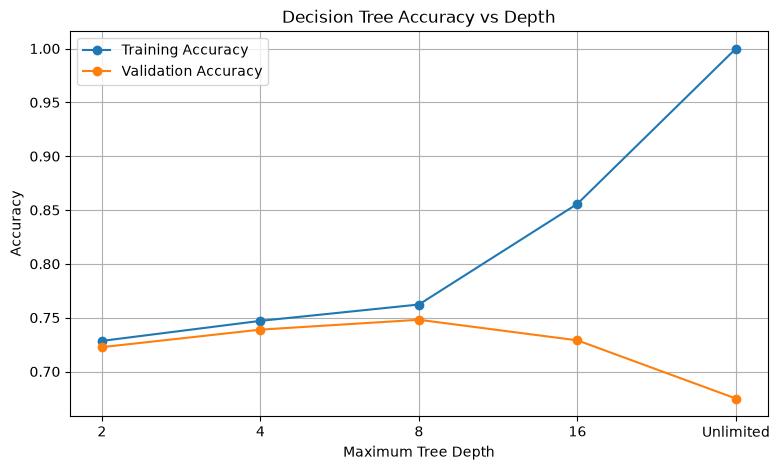

In [23]:

import matplotlib.pyplot as plt


plot_depths = [2, 4, 8, 16, "Unlimited"]

train_scores = results_df["Train Accuracy"]
val_scores = results_df["Validation Accuracy"]

plt.figure(figsize=(9, 5))

plt.plot(
    range(len(plot_depths)),
    train_scores,
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    range(len(plot_depths)),
    val_scores,
    marker="o",
    label="Validation Accuracy"
)

plt.xticks(range(len(plot_depths)), plot_depths)
plt.xlabel("Maximum Tree Depth")
plt.ylabel("Accuracy")
plt.title("Decision Tree Accuracy vs Depth")
plt.legend()
plt.grid(True)
plt.show()
